# WBC Classification with ResNeXt-50 - Colab Free Tier

This notebook preserves the requested pure-TensorFlow ResNeXt-50 architecture, TensorFlow/Keras + Optuna + Keras Tuner workflow, class weighting, and evaluation graphs. To fit a free Colab T4 session, it uses a deterministic training subset of at most 1,000 images per class, a batch size of 8, modest HPO budgets, and short three-stage schedules. Validation and test sets remain unchanged.

The subset rule, seed, run configuration, HPO results, and test metrics are saved to Drive so the experiment is auditable.

In [1]:
import subprocess
import sys

def pip_install_packages(*packages):
    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        *packages
    ])

pip_install_packages(
    "optuna==3.6.1",
    "keras-tuner==1.4.7",
    "ray[tune]==2.43.0",
)

import tensorflow as tf

print("TensorFlow Version:", tf.__version__)
print("Available Devices:", tf.config.list_physical_devices())

TensorFlow Version: 2.18.0
Available Devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
import os
import gc
import json
import random
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.gridspec as gridspec
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model, callbacks
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import CategoricalCrossentropy
from tensorflow.keras.metrics import AUC, Precision, Recall

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score,
    f1_score,
    accuracy_score,
    precision_score,
    recall_score,
)

from sklearn.preprocessing import label_binarize
from sklearn.manifold import TSNE

warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
plt.rcParams.update({"figure.dpi":120,"font.size":10})

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# --------------------------------------------------
# LOCAL DATASET PATH
# --------------------------------------------------

BASE_DIR = Path("Research_Dataset")

TRAIN_DIR = BASE_DIR / "train"
VAL_DIR = BASE_DIR / "val"
TEST_DIR = BASE_DIR / "test"

assert TRAIN_DIR.exists(), f"Missing folder: {TRAIN_DIR}"
assert VAL_DIR.exists(), f"Missing folder: {VAL_DIR}"
assert TEST_DIR.exists(), f"Missing folder: {TEST_DIR}"

CLASS_NAMES = sorted([f.name for f in TRAIN_DIR.iterdir() if f.is_dir()])
NUM_CLASSES = len(CLASS_NAMES)

print("Classes:", CLASS_NAMES)
print("Number of Classes:", NUM_CLASSES)

# --------------------------------------------------
# RESULTS
# --------------------------------------------------

RESULTS_DIR = Path("results")

MODEL_DIR = RESULTS_DIR / "models"
PLOT_DIR = RESULTS_DIR / "plots"
LOG_DIR = RESULTS_DIR / "logs"
METRICS_DIR = RESULTS_DIR / "metrics"
HISTORY_DIR = RESULTS_DIR / "history"

for folder in [
    MODEL_DIR,
    PLOT_DIR,
    LOG_DIR,
    METRICS_DIR,
    HISTORY_DIR,
]:
    folder.mkdir(parents=True, exist_ok=True)

IMG_SIZE = (224,224)

BATCH_SIZE = 8

MAX_TRAIN_IMAGES_PER_CLASS = 1000

STAGE_EPOCHS = (3,3,4)

STAGE_LRS = (1e-3,3e-4,1e-4)

OPTUNA_TRIALS = 2

HPO_EPOCHS = 2

RAY_SAMPLES = 2

EARLY_STOPPING_PATIENCE = 2

TSNE_SAMPLES = 900

gpus = tf.config.list_physical_devices("GPU")

print("TensorFlow:", tf.__version__)
print("GPU Devices:", gpus)

if gpus:
    for gpu in gpus:
        try:
            tf.config.experimental.set_memory_growth(gpu, True)
        except:
            pass

try:
    tf.keras.mixed_precision.set_global_policy("mixed_float16")
except:
    pass

strategy = tf.distribute.get_strategy()

print("Dataset:", BASE_DIR)
print("Strategy:", strategy)
print("Mixed Precision:", tf.keras.mixed_precision.global_policy())

Classes: ['Basophil', 'Blast', 'Eosinophil', 'Erythroblast', 'Giant Platelet', 'Lymphocyte', 'Monocyte', 'Neutrophil', 'ig']
Number of Classes: 9
TensorFlow: 2.18.0
GPU Devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Dataset: Research_Dataset
Strategy: <tensorflow.python.distribute.distribute_lib._DefaultDistributionStrategy object at 0x13099f4a0>
Mixed Precision: <DTypePolicy "mixed_float16">


In [3]:
# CELL 3 - Deterministic stratified training subset, class weights, and generators
VALID_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp'}

def build_train_manifest():
    rows = []
    for class_name in CLASS_NAMES:
        files = sorted([p for p in (TRAIN_DIR / class_name).iterdir() if p.is_file() and p.suffix.lower() in VALID_EXTENSIONS])
        rng = np.random.default_rng(SEED + CLASS_NAMES.index(class_name))
        take = min(len(files), MAX_TRAIN_IMAGES_PER_CLASS)
        chosen = rng.choice(files, size=take, replace=False) if take < len(files) else files
        rows.extend({'filepath': str(path), 'label': class_name} for path in chosen)
    manifest = pd.DataFrame(rows).sample(frac=1, random_state=SEED).reset_index(drop=True)
    assert len(manifest), 'No valid training images found.'
    return manifest

train_df = build_train_manifest()
train_df.to_csv(RESULTS_DIR / 'train_subset_manifest.csv', index=False)
CLASS_COUNTS = train_df['label'].value_counts().reindex(CLASS_NAMES, fill_value=0).to_dict()
total_images = len(train_df)
CLASS_WEIGHTS = {i: total_images / (NUM_CLASSES * max(CLASS_COUNTS[name], 1)) for i, name in enumerate(CLASS_NAMES)}

def build_generators(batch_size=BATCH_SIZE):
    train_aug = ImageDataGenerator(rescale=1.0 / 255, rotation_range=20, width_shift_range=0.10, height_shift_range=0.10, zoom_range=0.15, horizontal_flip=True, brightness_range=[0.85, 1.15], fill_mode='nearest')
    eval_aug = ImageDataGenerator(rescale=1.0 / 255)
    common = dict(target_size=IMG_SIZE, batch_size=batch_size, class_mode='categorical', classes=CLASS_NAMES, seed=SEED)
    train_gen = train_aug.flow_from_dataframe(train_df, x_col='filepath', y_col='label', shuffle=True, validate_filenames=True, **common)
    val_gen = eval_aug.flow_from_directory(str(VAL_DIR), shuffle=False, **common)
    test_gen = eval_aug.flow_from_directory(str(TEST_DIR), shuffle=False, **common)
    return train_gen, val_gen, test_gen

train_gen, val_gen, test_gen = build_generators()
print(pd.DataFrame({'class': CLASS_NAMES, 'training_images': [CLASS_COUNTS[c] for c in CLASS_NAMES], 'class_weight': [CLASS_WEIGHTS[i] for i in range(NUM_CLASSES)]}))
print('Subset train / full validation / full test:', train_gen.samples, val_gen.samples, test_gen.samples)

Found 8571 validated image filenames belonging to 9 classes.
Found 5157 images belonging to 9 classes.
Found 9535 images belonging to 9 classes.
            class  training_images  class_weight
0        Basophil             1000      0.952333
1           Blast              571      1.667834
2      Eosinophil             1000      0.952333
3    Erythroblast             1000      0.952333
4  Giant Platelet             1000      0.952333
5      Lymphocyte             1000      0.952333
6        Monocyte             1000      0.952333
7      Neutrophil             1000      0.952333
8              ig             1000      0.952333
Subset train / full validation / full test: 8571 5157 9535


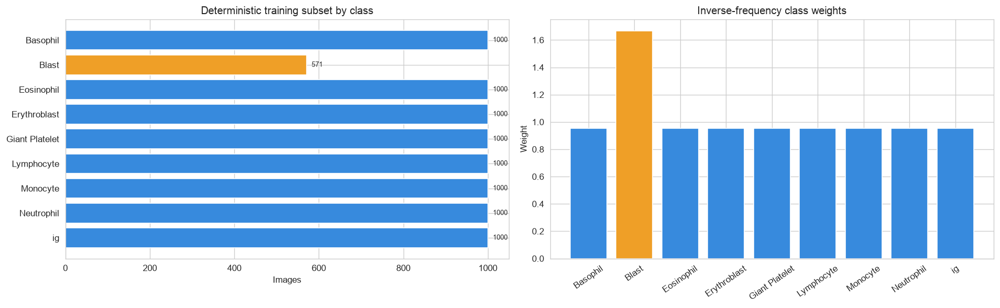

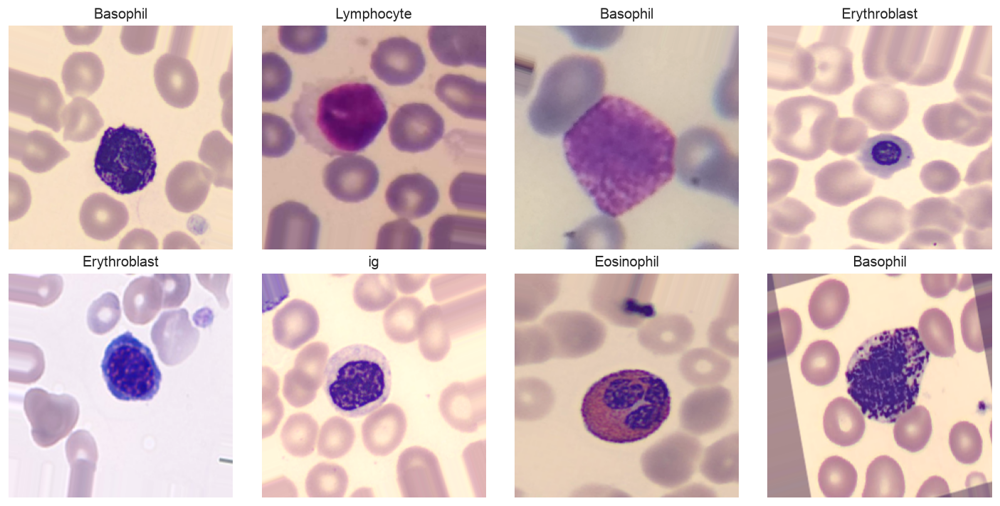

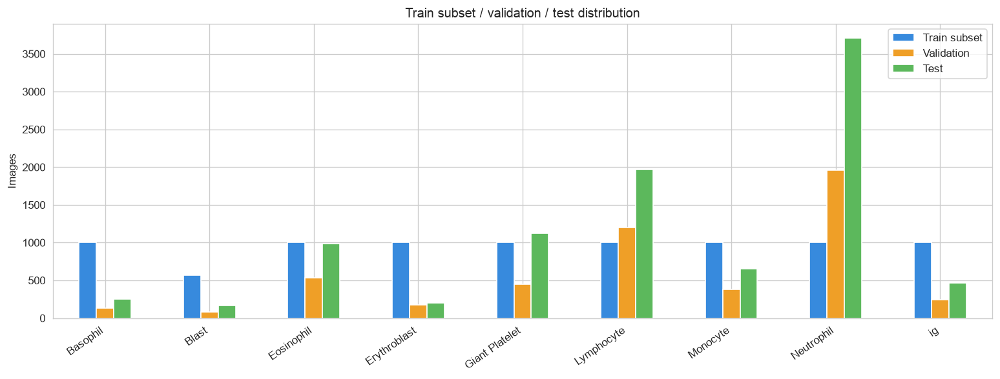

In [4]:
# CELL 4 - Dataset and augmentation visualizations
counts = [CLASS_COUNTS[c] for c in CLASS_NAMES]
colors = ['#E24B4A' if c < 500 else '#EF9F27' if c < 1000 else '#378ADD' for c in counts]
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
bars = axes[0].barh(CLASS_NAMES, counts, color=colors)
for bar, count in zip(bars, counts): axes[0].text(count + 12, bar.get_y() + bar.get_height() / 2, str(count), va='center', fontsize=8)
axes[0].set_title('Deterministic training subset by class'); axes[0].set_xlabel('Images'); axes[0].invert_yaxis()
axes[1].bar(CLASS_NAMES, [CLASS_WEIGHTS[i] for i in range(NUM_CLASSES)], color=colors)
axes[1].set_title('Inverse-frequency class weights'); axes[1].set_ylabel('Weight'); axes[1].tick_params(axis='x', rotation=35)
plt.tight_layout(); plt.savefig(PLOT_DIR / 'dataset_distribution_and_weights.png', dpi=200, bbox_inches='tight'); plt.show()

def show_augmentation_preview(generator, n=8):
    generator.reset(); images, labels = next(generator)
    fig, axes = plt.subplots(2, 4, figsize=(12, 6)); axes = axes.flatten()
    for idx, ax in enumerate(axes):
        ax.imshow(images[idx]); ax.set_title(CLASS_NAMES[int(np.argmax(labels[idx]))]); ax.axis('off')
    plt.tight_layout(); plt.savefig(PLOT_DIR / 'augmentation_preview.png', dpi=200, bbox_inches='tight'); plt.show()

show_augmentation_preview(train_gen)
split_counts = pd.DataFrame({'Train subset': counts, 'Validation': [int(np.sum(val_gen.classes == i)) for i in range(NUM_CLASSES)], 'Test': [int(np.sum(test_gen.classes == i)) for i in range(NUM_CLASSES)]}, index=CLASS_NAMES)
split_counts.plot(kind='bar', figsize=(13, 5), color=['#378ADD', '#EF9F27', '#5CB85C'])
plt.title('Train subset / validation / test distribution'); plt.ylabel('Images'); plt.xticks(rotation=35, ha='right'); plt.tight_layout()
plt.savefig(PLOT_DIR / 'split_distribution.png', dpi=200, bbox_inches='tight'); plt.show()

In [12]:
# CELL 5 - Pure TensorFlow ResNeXt-50 (native grouped convolutions)
L2_WEIGHT_DECAY = 1e-4
CARDINALITY = 32
EXPANSION = 4

def conv_bn_relu(x, filters, kernel_size, strides=1, groups=1, activation=True, name=None):
    x = layers.Conv2D(filters, kernel_size, strides=strides, padding='same', groups=1, use_bias=False, kernel_initializer='he_normal', kernel_regularizer=keras.regularizers.l2(L2_WEIGHT_DECAY), name=None if name is None else f'{name}_conv')(x)
    x = layers.BatchNormalization(momentum=0.9, epsilon=1e-5, name=None if name is None else f'{name}_bn')(x)
    return layers.ReLU(name=None if name is None else f'{name}_relu')(x) if activation else x

def resnext_block(x, filters, strides=1, projection=False, name='block'):
    shortcut = x
    x = conv_bn_relu(x, filters, 1, name=f'{name}_reduce')
    x = conv_bn_relu(x, filters, 3, strides=strides, groups=CARDINALITY, name=f'{name}_group')
    x = layers.Conv2D(filters * EXPANSION, 1, padding='same', use_bias=False, kernel_initializer='he_normal', kernel_regularizer=keras.regularizers.l2(L2_WEIGHT_DECAY), name=f'{name}_expand_conv')(x)
    x = layers.BatchNormalization(momentum=0.9, epsilon=1e-5, name=f'{name}_expand_bn')(x)
    if projection:
        shortcut = layers.Conv2D(filters * EXPANSION, 1, strides=strides, padding='same', use_bias=False, kernel_initializer='he_normal', kernel_regularizer=keras.regularizers.l2(L2_WEIGHT_DECAY), name=f'{name}_shortcut_conv')(shortcut)
        shortcut = layers.BatchNormalization(momentum=0.9, epsilon=1e-5, name=f'{name}_shortcut_bn')(shortcut)
    return layers.ReLU(name=f'{name}_out')(layers.Add(name=f'{name}_add')([x, shortcut]))

def make_stage(x, filters, blocks, stride, stage_name):
    x = resnext_block(x, filters, strides=stride, projection=True, name=f'{stage_name}_block1')
    for index in range(2, blocks + 1): x = resnext_block(x, filters, name=f'{stage_name}_block{index}')
    return x

def build_resnext50(dropout=0.30, dense_units=512):
    inputs = keras.Input(shape=(*IMG_SIZE, 3), name='input_image')
    x = conv_bn_relu(inputs, 64, 7, strides=2, name='stem')
    x = layers.MaxPooling2D(3, strides=2, padding='same', name='stem_pool')(x)
    x = make_stage(x, 64, 3, 1, 'stage1')
    x = make_stage(x, 128, 4, 2, 'stage2')
    x = make_stage(x, 256, 6, 2, 'stage3')
    x = make_stage(x, 512, 3, 2, 'stage4')
    x = layers.GlobalAveragePooling2D(name='global_average_pool')(x)
    x = layers.BatchNormalization(name='head_bn')(x)
    x = layers.Dense(dense_units, activation='relu', kernel_initializer='he_normal', kernel_regularizer=keras.regularizers.l2(L2_WEIGHT_DECAY), name='fc1')(x)
    x = layers.Dropout(dropout, name='dropout1')(x)
    x = layers.Dense(256, activation='relu', kernel_initializer='he_normal', kernel_regularizer=keras.regularizers.l2(L2_WEIGHT_DECAY), name='fc2')(x)
    x = layers.Dropout(dropout / 2, name='dropout2')(x)
    outputs = layers.Dense(NUM_CLASSES, activation='softmax', dtype='float32', name='classifier')(x)
    return keras.Model(inputs, outputs, name='ResNeXt50_WBC')

with strategy.scope(): model_check = build_resnext50()
print('Model parameters:', f'{model_check.count_params():,}')
del model_check; gc.collect()

Model parameters: 24,752,073


36443

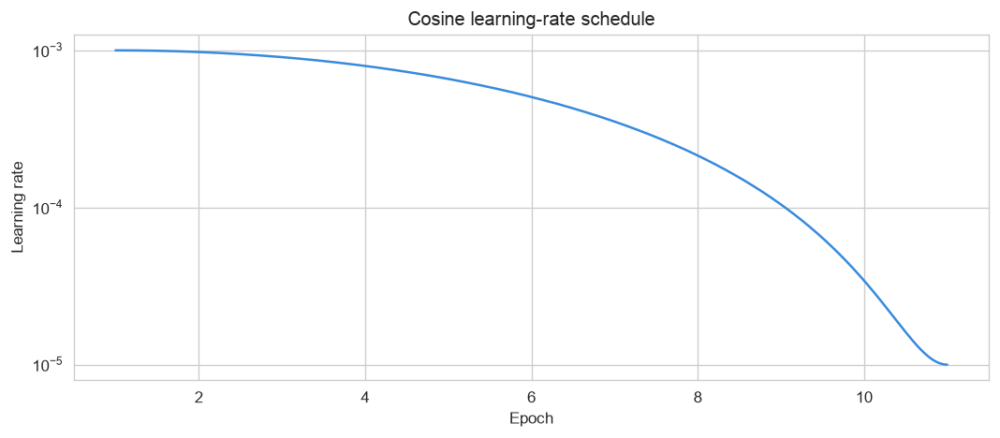

In [13]:
# CELL 6 - Compilation, callbacks, three-stage training, and curves
def compile_model(model, learning_rate):
    model.compile(optimizer=Adam(learning_rate=learning_rate), loss=CategoricalCrossentropy(label_smoothing=0.05), metrics=['accuracy', AUC(name='auc'), Precision(name='precision'), Recall(name='recall')])
    return model

def get_callbacks(tag, stage):
    prefix = f'{tag}_{stage}'
    return [
        callbacks.ModelCheckpoint(str(MODEL_DIR / f'{prefix}_best.keras'), monitor='val_auc', mode='max', save_best_only=True, verbose=0),
        callbacks.EarlyStopping(monitor='val_auc', mode='max', patience=EARLY_STOPPING_PATIENCE, restore_best_weights=True, verbose=0),
        callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=1, min_lr=1e-7, verbose=0),
        callbacks.CSVLogger(str(HISTORY_DIR / f'{prefix}.csv')),
    ]

def merge_histories(histories):
    merged = {}
    for history in histories:
        for key, values in history.history.items(): merged.setdefault(key, []).extend(values)
    return merged

def three_stage_train(tag, dropout=0.30, dense_units=512, lrs=STAGE_LRS, epochs=STAGE_EPOCHS):
    tf.keras.backend.clear_session(); gc.collect()
    with strategy.scope(): model = compile_model(build_resnext50(dropout=dropout, dense_units=dense_units), lrs[0])
    histories = []
    for stage_index, (learning_rate, stage_epochs) in enumerate(zip(lrs, epochs), start=1):
        if stage_index > 1: compile_model(model, learning_rate)
        print(f'{tag}: stage {stage_index}/3, lr={learning_rate}, epochs={stage_epochs}')
        histories.append(
            model.fit(
                train_gen,
                validation_data=val_gen,
                epochs=stage_epochs,
                class_weight=CLASS_WEIGHTS,
                callbacks=get_callbacks(tag, f"stage{stage_index}"),
                verbose=1
            )
        )
    final_path = MODEL_DIR / f'{tag}_final.keras'
    model.save(final_path)
    return {'model': model, 'history': merge_histories(histories), 'path': final_path}

def plot_training_curves(result, tag):
    history = result['history']; metrics = [('loss', 'val_loss'), ('accuracy', 'val_accuracy'), ('auc', 'val_auc')]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for axis, (metric, val_metric) in zip(axes, metrics):
        axis.plot(history.get(metric, []), label=metric); axis.plot(history.get(val_metric, []), label=val_metric)
        axis.set_title(metric.upper()); axis.set_xlabel('Epoch'); axis.legend()
    plt.suptitle(f'Training curves - {tag}'); plt.tight_layout(); plt.savefig(PLOT_DIR / f'curves_{tag}.png', dpi=180, bbox_inches='tight'); plt.show()

steps = sum(STAGE_EPOCHS) * len(train_gen)
schedule = tf.keras.optimizers.schedules.CosineDecay(STAGE_LRS[0], decay_steps=max(steps, 1), alpha=1e-2)
lr_values = [float(schedule(step)) for step in range(steps)]
plt.figure(figsize=(9, 4)); plt.plot(np.arange(steps) / len(train_gen) + 1, lr_values, color='#378ADD'); plt.yscale('log'); plt.xlabel('Epoch'); plt.ylabel('Learning rate'); plt.title('Cosine learning-rate schedule'); plt.tight_layout()
plt.savefig(PLOT_DIR / 'cosine_lr_schedule.png', dpi=180, bbox_inches='tight'); plt.show()

In [16]:
# CELL 7 - Evaluation, ROC/PR, Grad-CAM, t-SNE, and weight analysis
all_results = []

def predictions(model, generator):
    generator.reset(); probabilities = model.predict(generator, verbose=0); truth = generator.classes.copy(); return truth, np.argmax(probabilities, axis=1), probabilities

def evaluate_model(model, tag):
    y_true, y_pred, y_prob = predictions(model, test_gen)
    result = {'Model': tag, 'Accuracy': accuracy_score(y_true, y_pred), 'F1': f1_score(y_true, y_pred, average='macro'), 'Precision': precision_score(y_true, y_pred, average='macro', zero_division=0), 'Recall': recall_score(y_true, y_pred, average='macro', zero_division=0)}
    try: result['AUC'] = roc_auc_score(label_binarize(y_true, classes=range(NUM_CLASSES)), y_prob, average='macro', multi_class='ovr')
    except ValueError: result['AUC'] = np.nan
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, zero_division=0))
    matrix = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(10, 8)); sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES); plt.xlabel('Predicted'); plt.ylabel('True'); plt.title(f'Confusion matrix - {tag}'); plt.tight_layout()
    plt.savefig(PLOT_DIR / f'confusion_matrix_{tag}.png', dpi=180, bbox_inches='tight'); plt.show()
    pd.DataFrame([result]).to_csv(METRICS_DIR / f'metrics_{tag}.csv', index=False)
    return result

def plot_roc_pr(model, tag):
    y_true, _, y_prob = predictions(model, test_gen); y_bin = label_binarize(y_true, classes=range(NUM_CLASSES))
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for i, class_name in enumerate(CLASS_NAMES):
        if len(np.unique(y_bin[:, i])) < 2: continue
        fpr, tpr, _ = roc_curve(y_bin[:, i], y_prob[:, i]); axes[0].plot(fpr, tpr, label=class_name)
        precision, recall, _ = precision_recall_curve(y_bin[:, i], y_prob[:, i]); axes[1].plot(recall, precision, label=f'{class_name} AP={average_precision_score(y_bin[:, i], y_prob[:, i]):.2f}')
    axes[0].plot([0, 1], [0, 1], 'k--'); axes[0].set_title('ROC curves'); axes[1].set_title('Precision-recall curves')
    for axis in axes: axis.legend(fontsize=7); axis.grid(alpha=0.25)
    plt.tight_layout(); plt.savefig(PLOT_DIR / f'roc_pr_{tag}.png', dpi=180, bbox_inches='tight'); plt.show()

def show_gradcam(model, tag):
    import matplotlib
    conv_layers = [
        layer for layer in model.layers
        if isinstance(layer, layers.Conv2D)
    ]

    conv_name = conv_layers[-1].name
    grad_model = Model(model.inputs, [model.get_layer(conv_name).output, model.output])
    fig, axes = plt.subplots(2, NUM_CLASSES, figsize=(3 * NUM_CLASSES, 6)); shown = set(); test_gen.reset()
    for _ in range(len(test_gen)):
        images, labels = next(test_gen)
        for image, label in zip(images, labels):
            class_index = int(np.argmax(label))
            if class_index in shown: continue
            image_batch = image[None, ...]
            with tf.GradientTape() as tape:
                conv_output, probs = grad_model(image_batch); predicted = int(tf.argmax(probs[0])); score = probs[:, int(predicted)]
            gradients = tape.gradient(score, conv_output); weights = tf.reduce_mean(gradients, axis=(0, 1, 2))
            heatmap = tf.squeeze(conv_output[0] @ weights[..., None]); heatmap = tf.maximum(heatmap, 0) / (tf.reduce_max(heatmap) + 1e-8)
            heatmap = tf.image.resize(heatmap[..., None], IMG_SIZE).numpy().squeeze(); overlay = matplotlib.colormaps["jet"](heatmap)[..., :3] * 0.45 + image * 0.55
            axes[0, class_index].imshow(image); axes[0, class_index].set_title(CLASS_NAMES[class_index]); axes[0, class_index].axis('off')
            axes[1, class_index].imshow(np.clip(overlay, 0, 1)); axes[1, class_index].set_title(f'Pred: {CLASS_NAMES[int(predicted)]}'); axes[1, class_index].axis('off'); shown.add(class_index)
            if len(shown) == NUM_CLASSES: break
        if len(shown) == NUM_CLASSES: break
    plt.suptitle(f'Grad-CAM - {tag}'); plt.tight_layout(); plt.savefig(PLOT_DIR / f'gradcam_{tag}.png', dpi=150, bbox_inches='tight'); plt.show()

def plot_tsne(model, tag):
    feature_model = Model(model.inputs, model.get_layer('global_average_pool').output); test_gen.reset(); features = []; labels = []
    while sum(len(batch) for batch in labels) < TSNE_SAMPLES:
        images, batch_labels = next(test_gen); features.append(feature_model.predict(images, verbose=0)); labels.append(np.argmax(batch_labels, axis=1))
    features = np.concatenate(features)[:TSNE_SAMPLES]; labels = np.concatenate(labels)[:TSNE_SAMPLES]
    embedding = TSNE(n_components=2, perplexity=min(30, max(5, len(features) // 20)), init='pca', learning_rate='auto', random_state=SEED).fit_transform(features)
    plt.figure(figsize=(9, 7))
    for index, class_name in enumerate(CLASS_NAMES):
        mask = labels == index; plt.scatter(embedding[mask, 0], embedding[mask, 1], s=10, alpha=0.65, label=class_name)
    plt.legend(fontsize=8); plt.title(f't-SNE feature space - {tag}'); plt.tight_layout(); plt.savefig(PLOT_DIR / f'tsne_{tag}.png', dpi=180, bbox_inches='tight'); plt.show()

def plot_weight_analysis(model, tag):
    convs = [layer for layer in model.layers if isinstance(layer, layers.Conv2D) and layer.get_weights()]
    stds = [layer.get_weights()[0].std() for layer in convs]
    fig, axes = plt.subplots(1, 2, figsize=(13, 4)); axes[0].hist(convs[0].get_weights()[0].ravel(), bins=60, alpha=0.8, label=convs[0].name); axes[0].hist(convs[-1].get_weights()[0].ravel(), bins=60, alpha=0.55, label=convs[-1].name); axes[0].legend(fontsize=7); axes[0].set_title('Early and late convolution weights')
    axes[1].plot(stds, 'o-', color='#378ADD', markersize=3); axes[1].set_title('Convolution weight standard deviation'); axes[1].set_xlabel('Convolution depth'); axes[1].set_ylabel('Weight std')
    plt.tight_layout(); plt.savefig(PLOT_DIR / f'weights_{tag}.png', dpi=180, bbox_inches='tight'); plt.show()

resnext50_baseline: stage 1/3, lr=0.001, epochs=3
Epoch 1/3
1072/1072 ━━━━━━━━━━━━━━━━━━━━ 486s 437ms/step - accuracy: 0.1790 - auc: 0.5658 - loss: 21.3693 - precision: 0.1816 - recall: 0.1724 - val_accuracy: 0.0543 - val_auc: 0.4658 - val_loss: 57.6487 - val_precision: 0.0557 - val_recall: 0.0533 - learning_rate: 0.0010
Epoch 2/3
1072/1072 ━━━━━━━━━━━━━━━━━━━━ 574s 535ms/step - accuracy: 0.2238 - auc: 0.6235 - loss: 10.4082 - precision: 0.2335 - recall: 0.2039 - val_accuracy: 0.1317 - val_auc: 0.6829 - val_loss: 7.2569 - val_precision: 0.1550 - val_recall: 0.1193 - learning_rate: 0.0010
Epoch 3/3
1072/1072 ━━━━━━━━━━━━━━━━━━━━ 515s 480ms/step - accuracy: 0.2457 - auc: 0.6406 - loss: 8.7646 - precision: 0.2521 - recall: 0.2228 - val_accuracy: 0.1716 - val_auc: 0.6140 - val_loss: 9.1128 - val_precision: 0.1739 - val_recall: 0.1321 - learning_rate: 0.0010
resnext50_baseline: stage 2/3, lr=0.0003, epochs=3
Epoch 1/3
1072/1072 ━━━━━━━━━━━━━━━━━━━━ 501s 453ms/step - accuracy: 0.2126 - auc: 

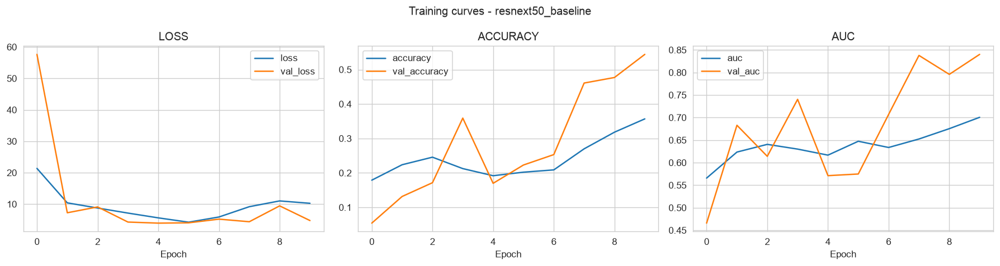

                precision    recall  f1-score   support

      Basophil       0.22      0.43      0.29       250
         Blast       0.08      0.97      0.15       164
    Eosinophil       0.41      0.50      0.45       988
  Erythroblast       0.31      0.52      0.39       204
Giant Platelet       0.93      0.84      0.88      1127
    Lymphocyte       0.92      0.13      0.23      1968
      Monocyte       0.44      0.25      0.32       651
    Neutrophil       0.88      0.86      0.87      3713
            ig       0.37      0.20      0.26       470

      accuracy                           0.58      9535
     macro avg       0.51      0.52      0.43      9535
  weighted avg       0.75      0.58      0.59      9535



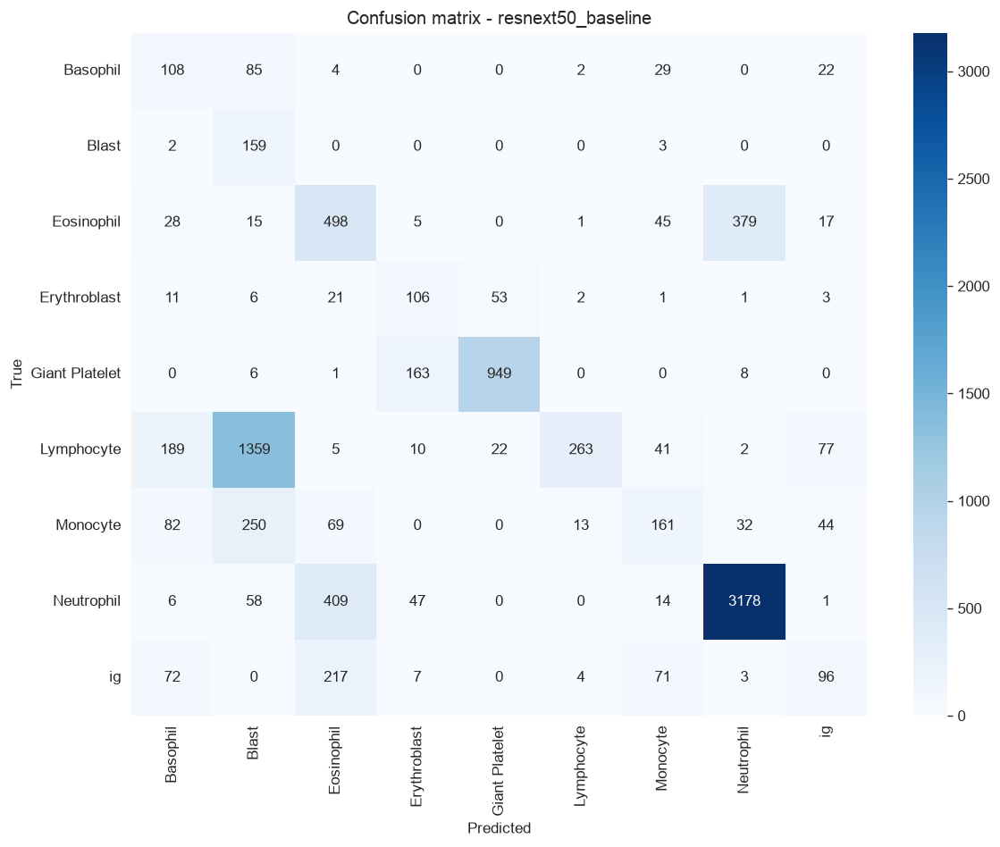

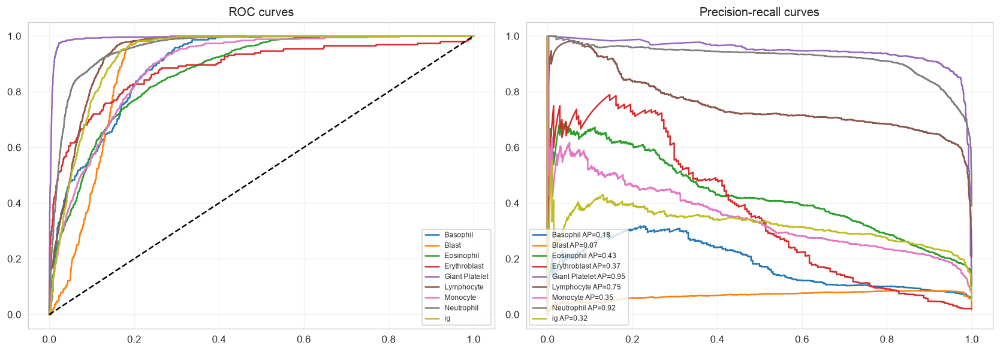

AttributeError: module 'matplotlib.cm' has no attribute 'get_cmap'

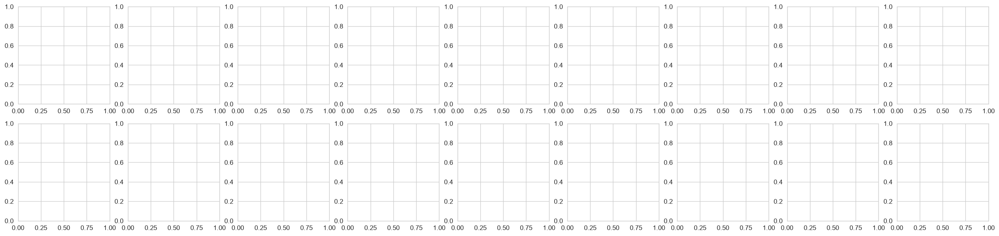

In [15]:
# CELL 8 - Baseline ResNeXt-50 run
baseline_res = three_stage_train('resnext50_baseline')
plot_training_curves(baseline_res, 'resnext50_baseline')
all_results.append(evaluate_model(baseline_res['model'], 'resnext50_baseline'))
plot_roc_pr(baseline_res['model'], 'resnext50_baseline')
show_gradcam(baseline_res['model'], 'resnext50_baseline')
plot_tsne(baseline_res['model'], 'resnext50_baseline')
plot_weight_analysis(baseline_res['model'], 'resnext50_baseline')

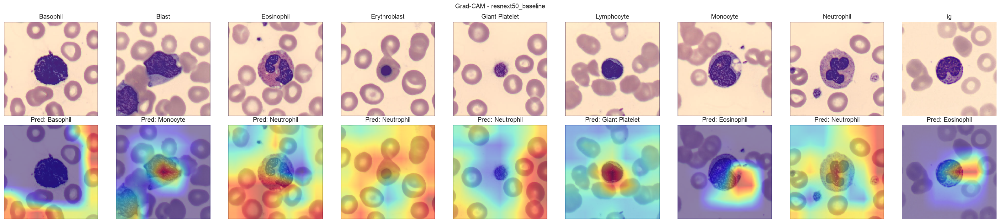

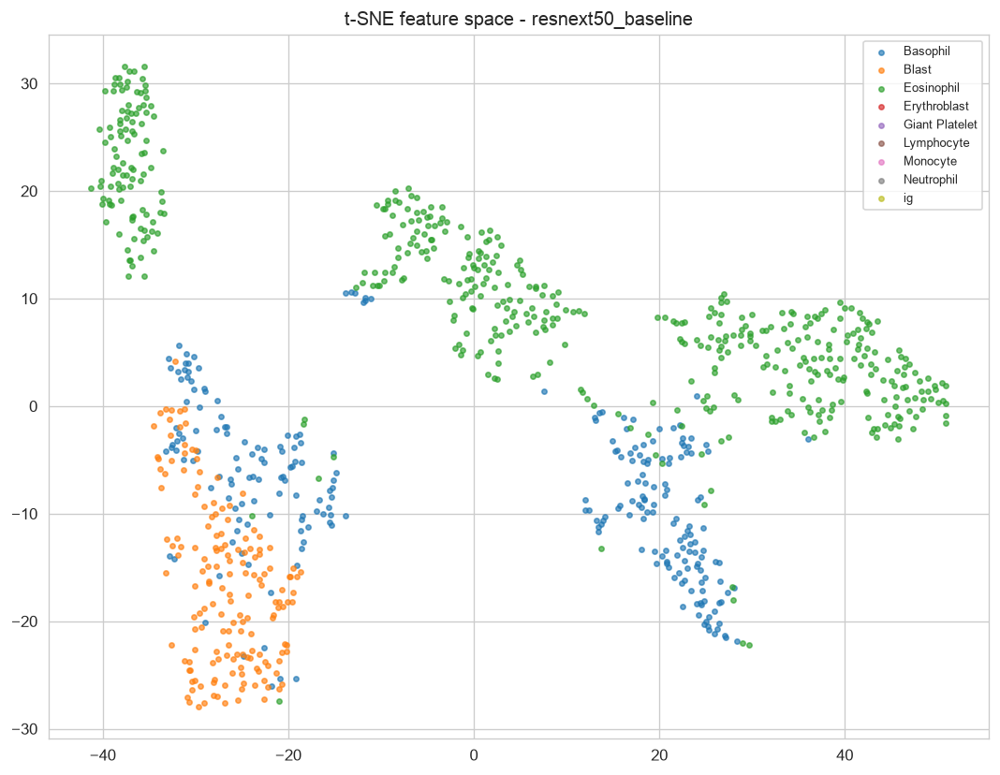

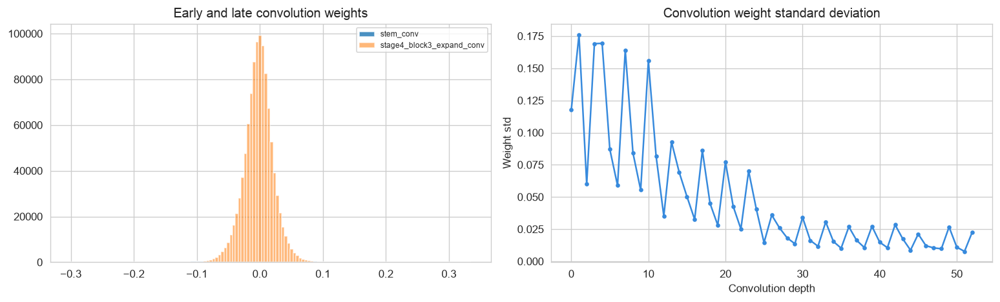

In [17]:
from tensorflow import keras

baseline_model = keras.models.load_model(
    MODEL_DIR / "resnext50_baseline_final.keras"
)

show_gradcam(baseline_model, "resnext50_baseline")
plot_tsne(baseline_model, "resnext50_baseline")
plot_weight_analysis(baseline_model, "resnext50_baseline")

Optuna best: {'lr': 0.00023688639503640813, 'dropout': 0.3901428612819833, 'dense': 256} AUC: 0.8937751650810242
resnext50_optuna: stage 1/3, lr=0.00023688639503640813, epochs=3
Epoch 1/3
1072/1072 ━━━━━━━━━━━━━━━━━━━━ 767s 698ms/step - accuracy: 0.2776 - auc: 0.6549 - loss: 11.9270 - precision: 0.2835 - recall: 0.2584 - val_accuracy: 0.4177 - val_auc: 0.8825 - val_loss: 7.2453 - val_precision: 0.4577 - val_recall: 0.3585 - learning_rate: 2.3689e-04
Epoch 2/3
1072/1072 ━━━━━━━━━━━━━━━━━━━━ 564s 525ms/step - accuracy: 0.3728 - auc: 0.7399 - loss: 10.2214 - precision: 0.3861 - recall: 0.3569 - val_accuracy: 0.3731 - val_auc: 0.8253 - val_loss: 8.1280 - val_precision: 0.3767 - val_recall: 0.3452 - learning_rate: 2.3689e-04
Epoch 3/3
1072/1072 ━━━━━━━━━━━━━━━━━━━━ 539s 502ms/step - accuracy: 0.5023 - auc: 0.8284 - loss: 8.4133 - precision: 0.5227 - recall: 0.4870 - val_accuracy: 0.6543 - val_auc: 0.9057 - val_loss: 7.3818 - val_precision: 0.6703 - val_recall: 0.6372 - learning_rate: 1.1844

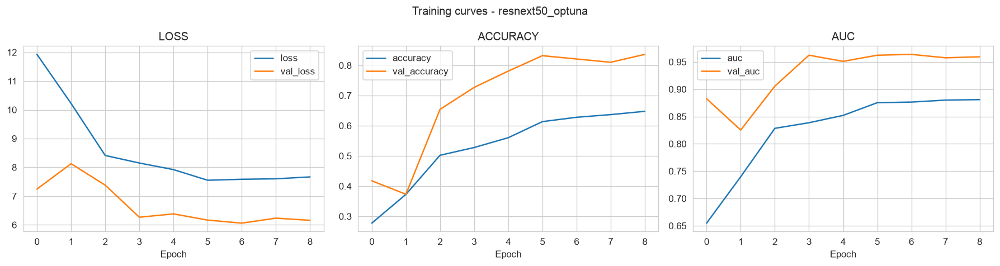

                precision    recall  f1-score   support

      Basophil       0.86      0.88      0.87       250
         Blast       0.45      0.90      0.60       164
    Eosinophil       0.97      0.93      0.95       988
  Erythroblast       0.65      0.90      0.76       204
Giant Platelet       1.00      0.97      0.99      1127
    Lymphocyte       0.95      0.79      0.86      1968
      Monocyte       0.58      0.60      0.59       651
    Neutrophil       1.00      0.91      0.95      3713
            ig       0.47      0.93      0.62       470

      accuracy                           0.87      9535
     macro avg       0.77      0.87      0.80      9535
  weighted avg       0.91      0.87      0.88      9535



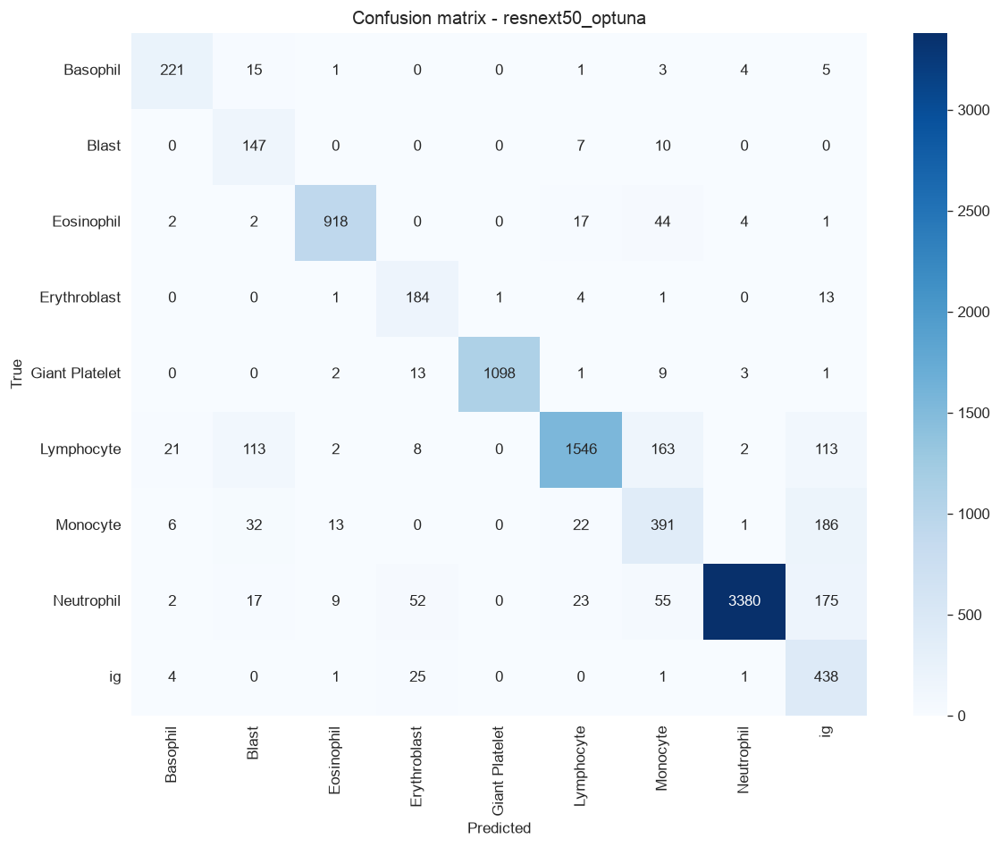

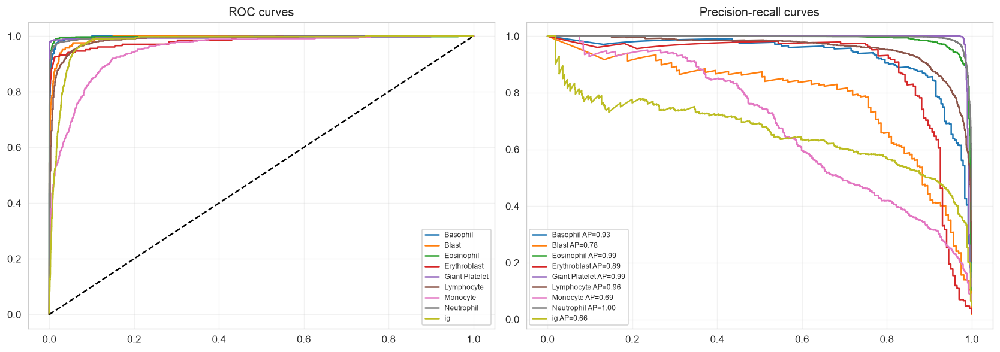

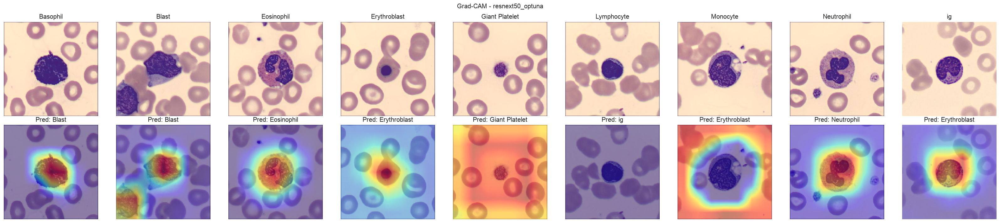

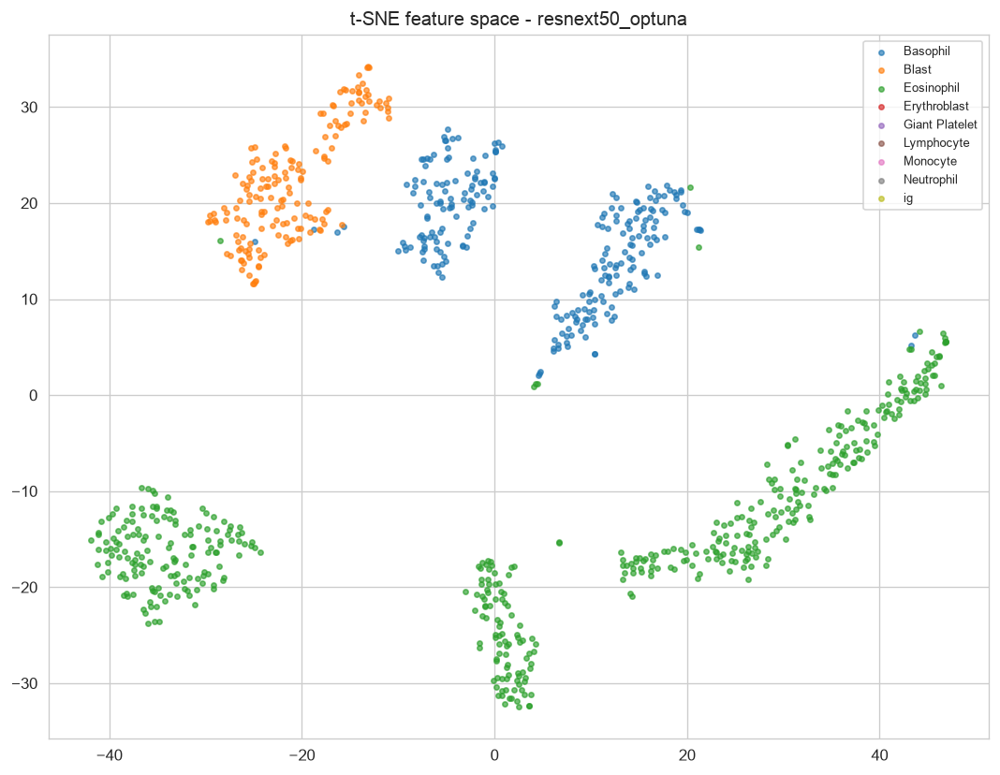

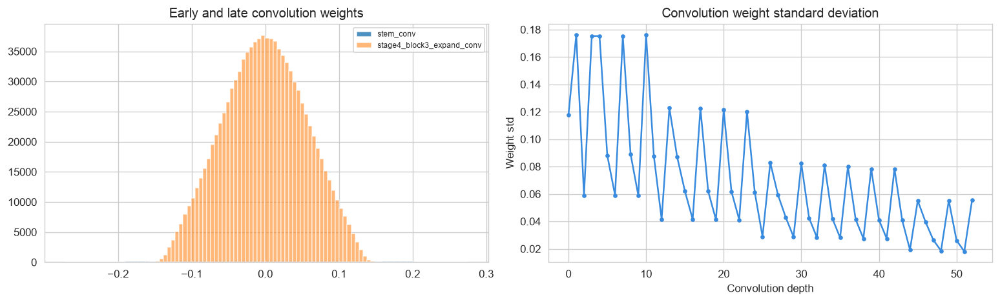

In [18]:
# CELL 9 - Optuna (TPE + MedianPruner) and final Optuna model
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

def optuna_objective(trial):
    tf.keras.backend.clear_session(); gc.collect()
    learning_rate = trial.suggest_float('lr', 1e-4, 1e-3, log=True)
    dropout = trial.suggest_float('dropout', 0.20, 0.40)
    dense_units = trial.suggest_categorical('dense', [256, 512])
    with strategy.scope():
        model = compile_model(
            build_resnext50(
                dropout=dropout,
                dense_units=dense_units
            ),
            learning_rate
        )
    class PruneCallback(callbacks.Callback):
        def on_epoch_end(self, epoch, logs=None):
            trial.report((logs or {}).get('val_auc', 0.0), epoch)
            if trial.should_prune(): raise optuna.TrialPruned()
    gc.collect()
    history = model.fit(train_gen, validation_data=val_gen, epochs=HPO_EPOCHS, class_weight=CLASS_WEIGHTS, callbacks=[PruneCallback()], verbose=0)
    return max(history.history.get('val_auc', [0.0]))

optuna_study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED), pruner=optuna.pruners.MedianPruner(n_startup_trials=1, n_warmup_steps=1))
optuna_study.optimize(optuna_objective, n_trials=OPTUNA_TRIALS, show_progress_bar=False)
optuna_best = optuna_study.best_params
optuna_values = [trial.value for trial in optuna_study.trials if trial.value is not None]
print('Optuna best:', optuna_best, 'AUC:', optuna_study.best_value)
optuna_res = three_stage_train('resnext50_optuna', dropout=optuna_best['dropout'], dense_units=optuna_best['dense'], lrs=(optuna_best['lr'], optuna_best['lr'] / 3, optuna_best['lr'] / 10))
plot_training_curves(optuna_res, 'resnext50_optuna')
all_results.append(evaluate_model(optuna_res['model'], 'resnext50_optuna'))
plot_roc_pr(optuna_res['model'], 'resnext50_optuna'); show_gradcam(optuna_res['model'], 'resnext50_optuna'); plot_tsne(optuna_res['model'], 'resnext50_optuna'); plot_weight_analysis(optuna_res['model'], 'resnext50_optuna')

In [19]:
SEED = 42
HPO_EPOCHS = 2

Keras Tuner best: {'lr': 0.00018701455766499827, 'dropout': 0.4, 'dense': 256}
resnext50_keras_tuner: stage 1/3, lr=0.00018701455766499827, epochs=3
Epoch 1/3
1072/1072 ━━━━━━━━━━━━━━━━━━━━ 1540s 1s/step - accuracy: 0.2595 - auc: 0.6496 - loss: 11.5416 - precision: 0.2689 - recall: 0.2415 - val_accuracy: 0.4958 - val_auc: 0.8250 - val_loss: 7.8402 - val_precision: 0.5225 - val_recall: 0.4429 - learning_rate: 1.8701e-04
Epoch 2/3
1072/1072 ━━━━━━━━━━━━━━━━━━━━ 1082s 1s/step - accuracy: 0.3779 - auc: 0.7414 - loss: 10.0598 - precision: 0.3889 - recall: 0.3603 - val_accuracy: 0.6271 - val_auc: 0.8965 - val_loss: 7.3777 - val_precision: 0.6462 - val_recall: 0.6130 - learning_rate: 1.8701e-04
Epoch 3/3
1072/1072 ━━━━━━━━━━━━━━━━━━━━ 23537s 22s/step - accuracy: 0.4012 - auc: 0.7498 - loss: 10.2336 - precision: 0.4108 - recall: 0.3885 - val_accuracy: 0.6694 - val_auc: 0.9064 - val_loss: 7.3957 - val_precision: 0.6955 - val_recall: 0.6465 - learning_rate: 1.8701e-04
resnext50_keras_tuner: stag

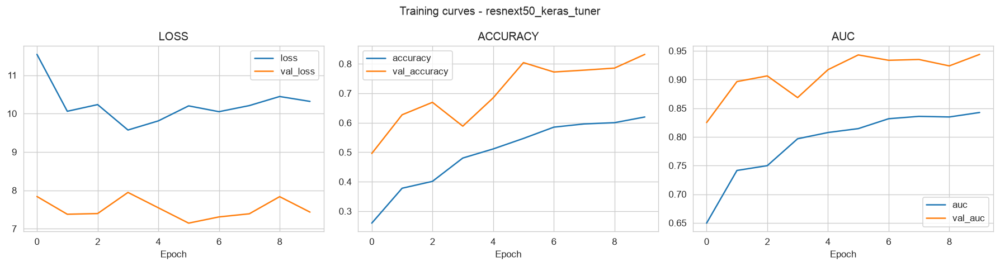

                precision    recall  f1-score   support

      Basophil       0.85      0.97      0.90       250
         Blast       0.32      0.95      0.48       164
    Eosinophil       0.82      0.86      0.84       988
  Erythroblast       0.63      0.75      0.68       204
Giant Platelet       0.97      0.97      0.97      1127
    Lymphocyte       0.85      0.81      0.83      1968
      Monocyte       0.81      0.63      0.71       651
    Neutrophil       0.98      0.92      0.95      3713
            ig       0.79      0.80      0.80       470

      accuracy                           0.87      9535
     macro avg       0.78      0.85      0.79      9535
  weighted avg       0.89      0.87      0.88      9535



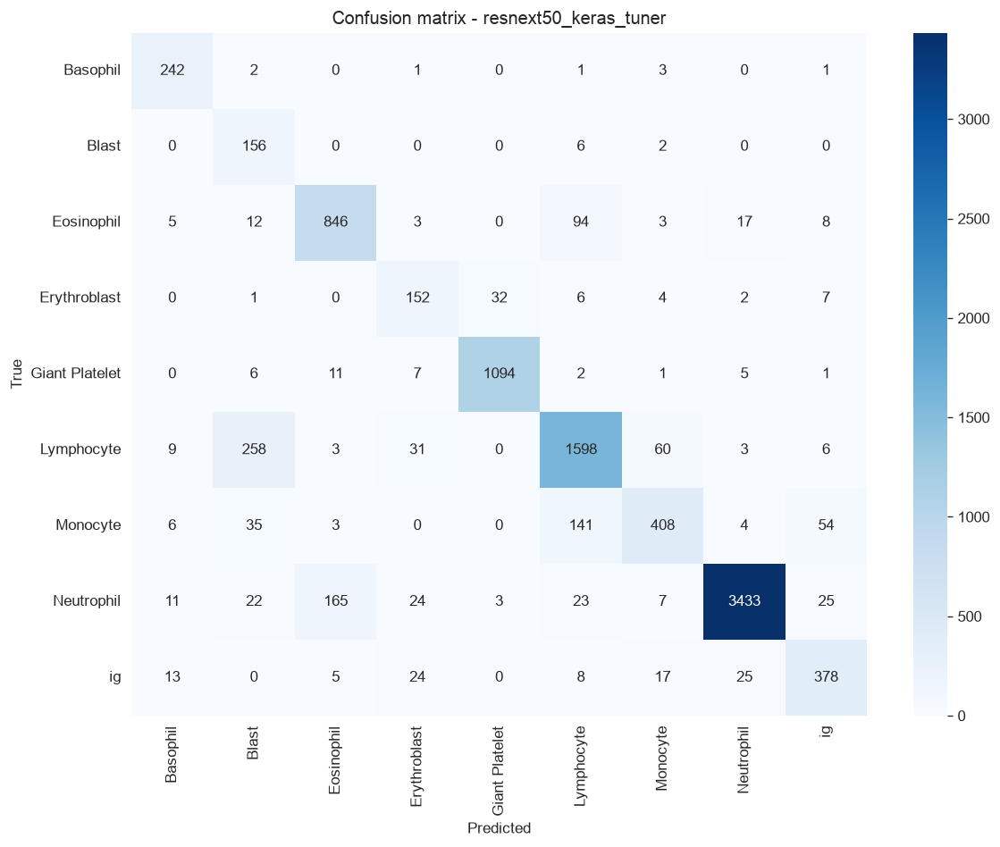

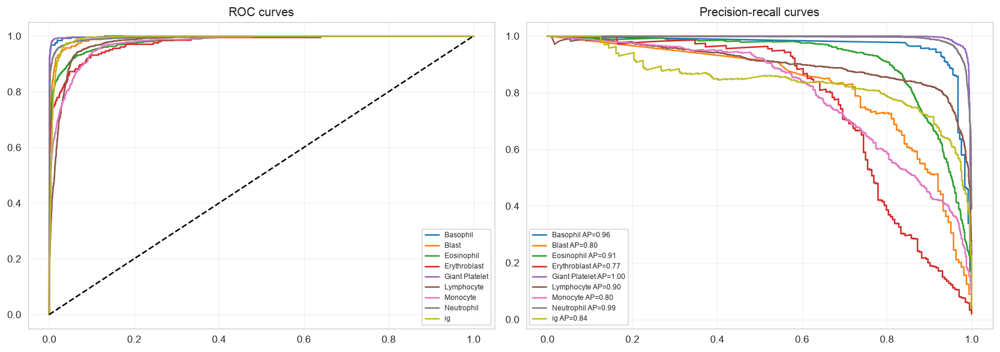

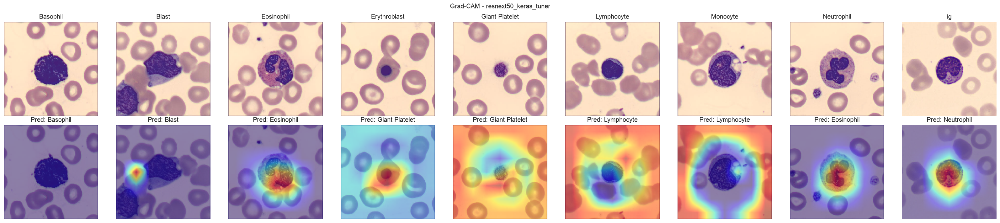

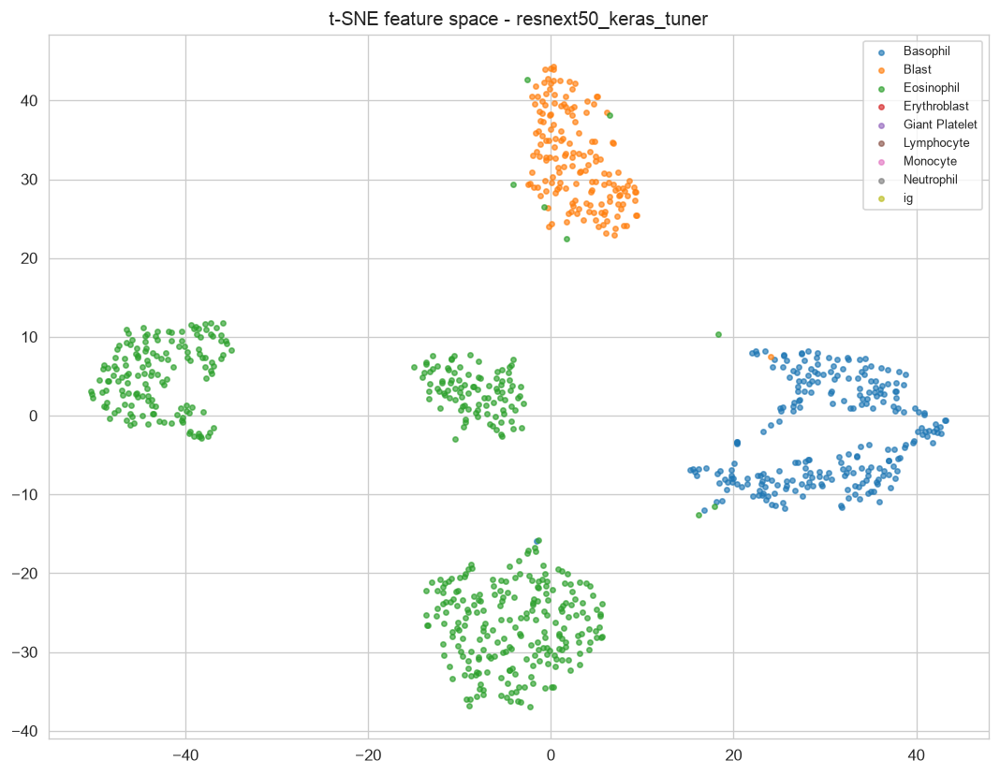

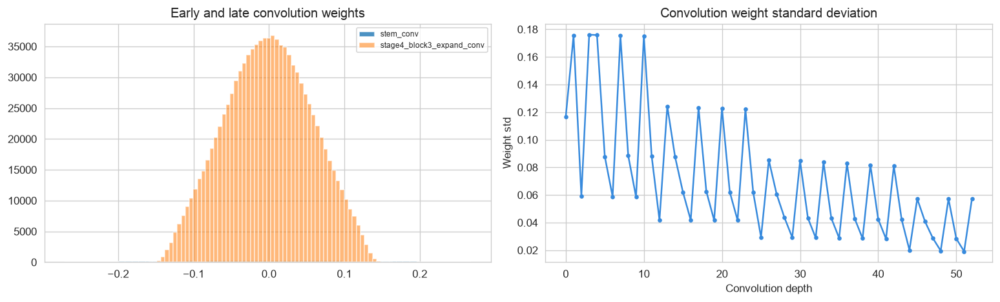

In [20]:
# CELL 10 - Keras Tuner Hyperband and final Keras Tuner model
import keras_tuner as kt

def kt_build(hp):
    learning_rate = hp.Float('lr', 1e-4, 1e-3, sampling='log')
    dropout = hp.Float('dropout', 0.20, 0.40, step=0.10)
    dense_units = hp.Choice('dense', [256, 512])
    return compile_model(build_resnext50(dropout=dropout, dense_units=dense_units), learning_rate)

kt_tuner = kt.Hyperband(kt_build, objective=kt.Objective('val_auc', direction='max'), max_epochs=HPO_EPOCHS, factor=2, hyperband_iterations=1, seed=SEED, directory=str(LOG_DIR / 'keras_tuner'), project_name='resnext50', overwrite=True)
kt_tuner.search(train_gen, validation_data=val_gen, class_weight=CLASS_WEIGHTS, callbacks=[callbacks.EarlyStopping(monitor='val_auc', mode='max', patience=1)], verbose=0)
kt_hp = kt_tuner.get_best_hyperparameters(1)[0]
keras_tuner_best = {'lr': kt_hp.get('lr'), 'dropout': kt_hp.get('dropout'), 'dense': kt_hp.get('dense')}
kt_scores = [trial.score for trial in kt_tuner.oracle.trials.values() if trial.score is not None]
print('Keras Tuner best:', keras_tuner_best)
kt_res = three_stage_train('resnext50_keras_tuner', dropout=keras_tuner_best['dropout'], dense_units=keras_tuner_best['dense'], lrs=(keras_tuner_best['lr'], keras_tuner_best['lr'] / 3, keras_tuner_best['lr'] / 10))
plot_training_curves(kt_res, 'resnext50_keras_tuner')
all_results.append(evaluate_model(kt_res['model'], 'resnext50_keras_tuner'))
plot_roc_pr(kt_res['model'], 'resnext50_keras_tuner'); show_gradcam(kt_res['model'], 'resnext50_keras_tuner'); plot_tsne(kt_res['model'], 'resnext50_keras_tuner'); plot_weight_analysis(kt_res['model'], 'resnext50_keras_tuner')

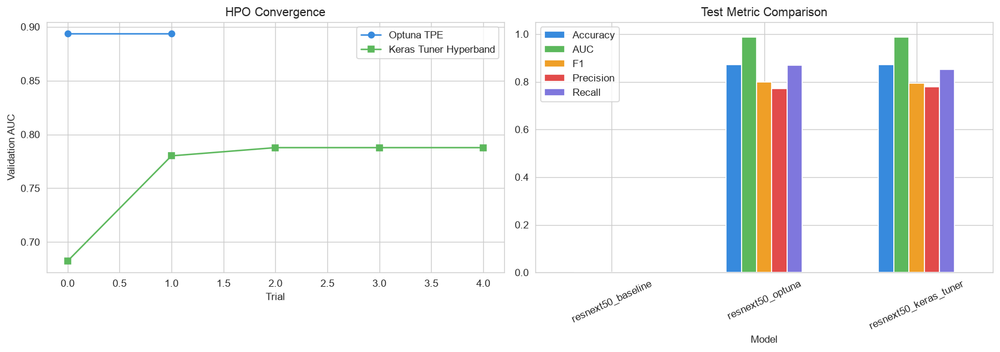

,Model,Accuracy,F1,Precision,Recall,AUC
0,resnext50_baseline,nan,nan,nan,nan,nan
1,resnext50_optuna,0.8729,0.7991,0.7702,0.8682,0.9865
2,resnext50_keras_tuner,0.8712,0.7948,0.7788,0.8510,0.9866


Best model: resnext50_optuna Composite=0.8594
Results saved to: results


In [ ]:
# CELL 11 - HPO comparison, final table, and reproducibility summary

results_df = pd.DataFrame(all_results)

order = [
    'resnext50_baseline',
    'resnext50_optuna',
    'resnext50_keras_tuner'
]

results_df = (
    results_df
    .set_index('Model')
    .reindex(order)
    .reset_index()
)

results_df.to_csv(RESULTS_DIR / 'final_results.csv', index=False)

# -----------------------------
# HPO convergence + metrics plot
# -----------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

if optuna_values:
    axes[0].plot(
        np.maximum.accumulate(optuna_values),
        'o-',
        label='Optuna TPE',
        color='#378ADD'
    )

if kt_scores:
    axes[0].plot(
        np.maximum.accumulate(kt_scores),
        's-',
        label='Keras Tuner Hyperband',
        color='#5CB85C'
    )

axes[0].set_title('HPO Convergence')
axes[0].set_xlabel('Trial')
axes[0].set_ylabel('Validation AUC')
axes[0].legend()

numeric_cols = [
    'Accuracy',
    'AUC',
    'F1',
    'Precision',
    'Recall'
]

results_df.plot(
    x='Model',
    y=numeric_cols,
    kind='bar',
    ax=axes[1],
    color=[
        '#378ADD',
        '#5CB85C',
        '#EF9F27',
        '#E24B4A',
        '#7F77DD'
    ]
)

axes[1].set_title('Test Metric Comparison')
axes[1].set_ylim(0, 1.05)
axes[1].tick_params(axis='x', rotation=25)

plt.tight_layout()
plt.savefig(
    PLOT_DIR / 'hpo_and_metric_comparison.png',
    dpi=180,
    bbox_inches='tight'
)
plt.show()

# -----------------------------
# Display results
# -----------------------------
try:
    display(
        results_df.style
        .format({c: "{:.4f}" for c in numeric_cols})
        .highlight_max(
            subset=numeric_cols,
            color="#B8E6C1"
        )
    )
except Exception:
    print(results_df)

# -----------------------------
# Composite score
# -----------------------------
results_df["Composite"] = results_df[numeric_cols].mean(axis=1)

best = results_df.loc[
    results_df["Composite"].idxmax()
]

# -----------------------------
# Summary JSON
# -----------------------------
summary = {
    "generated_at": datetime.now().isoformat(),
    "model": "ResNeXt-50 pure TensorFlow grouped convolution",
    "seed": SEED,
    "dataset_zip": "Research_Dataset.zip",
    "subset": {
        "max_train_images_per_class": MAX_TRAIN_IMAGES_PER_CLASS,
        "train_counts": CLASS_COUNTS,
        "manifest": "train_subset_manifest.csv"
    },
    "validation_images": int(val_gen.samples),
    "test_images": int(test_gen.samples),
    "class_weights": CLASS_WEIGHTS,
    "training": {
        "batch_size": BATCH_SIZE,
        "stage_epochs": STAGE_EPOCHS,
        "stage_lrs": STAGE_LRS
    },
    "hpo": {
        "optuna": optuna_best,
        "keras_tuner": keras_tuner_best
    },
    "results": results_df.drop(
        columns="Composite"
    ).to_dict(orient="records")
}

with open(
    RESULTS_DIR / "summary.json",
    "w"
) as file:
    json.dump(summary, file, indent=2, default=str)

print(
    "Best model:",
    best["Model"],
    "Composite={:.4f}".format(best["Composite"])
)

print("Results saved to:", RESULTS_DIR)

In [1]:
import platform
import sys
import tensorflow as tf
import keras_tuner as kt
import optuna

print("Machine:", platform.machine())
print("Platform:", platform.platform())
print("Processor:", platform.processor())
print("Python:", sys.version)
print("TensorFlow:", tf.__version__)
print("Optuna:", optuna.__version__)
print("Keras Tuner:", kt.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

Matplotlib is building the font cache; this may take a moment.


Machine: arm64
Platform: macOS-26.5.2-arm64-arm-64bit
Processor: arm
Python: 3.12.13 (main, Mar  3 2026, 12:39:30) [Clang 21.0.0 (clang-2100.0.123.102)]
TensorFlow: 2.18.0
Optuna: 4.3.0
Keras Tuner: 1.4.7
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


/Users/vidishagoel/Downloads/WBC_Project/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
